In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from scipy.io import wavfile
import scipy.io
from scipy.fft import rfft, fftfreq
from sklearn import svm

d = os.listdir()

if "model_1" in d:
    os.chdir("model_1") # Just some logic to be able to re-run cell in Jupyter notebook, as multiple runs changes the cwd.

print("Imports complete")
print("Running from: " + os.getcwd())
print("Please place dataset *one level up* from this folder.")
os.chdir("..")

Imports complete
Running from: C:\Users\leona\Documents\Krona\Hoost 2026\AI and Machine Learning\Project\model_1
Please place dataset *one level up* from this folder.


In [2]:
train_path = r"\IDMT-ISA-ELECTRIC-ENGINE\train_cut/"
t_path_good = os.getcwd() + train_path + "engine1_good"
t_path_broken = os.getcwd() + train_path + "engine2_broken"
t_path_heavy = os.getcwd() + train_path + "engine3_heavyload"

good_samples_count = len(os.listdir(t_path_good))
broken_samples_count = len(os.listdir(t_path_broken))
heavy_samples_count = len(os.listdir(t_path_heavy))

rate, test = wavfile.read(os.path.join(t_path_good, os.listdir(t_path_good)[0]))
good_n = test.shape[0] # Each WAV file happens to be same amount of samples, so no need to test all of them.

train_good = np.zeros((good_samples_count, good_n))
train_broken = np.zeros((broken_samples_count, good_n))
train_heavy = np.zeros((heavy_samples_count, good_n))

print("Reading train_cut_good...")
for idx, e in enumerate(os.listdir(t_path_good)):
    _, data = wavfile.read(os.path.join(t_path_good, e))
    train_good[idx] = data
    
print("Reading train_cut_bad...")
for idx, e in enumerate(os.listdir(t_path_broken)):
    _, data = wavfile.read(os.path.join(t_path_broken, e))
    train_broken[idx] = data
    
print("Reading train_cut_heavy...")
for idx, e in enumerate(os.listdir(t_path_heavy)):
    _, data = wavfile.read(os.path.join(t_path_heavy, e))
    train_heavy[idx] = data

print("Done.")

Reading train_cut_good...
Reading train_cut_bad...
Reading train_cut_heavy...
Done.


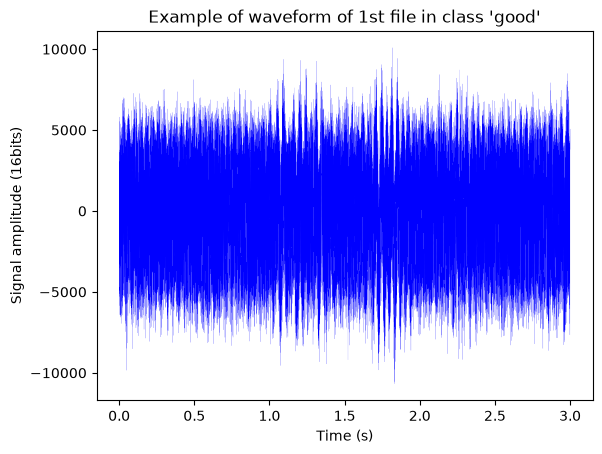

In [3]:
t = np.arange(0.0, 3.0, 1/rate)

plt.figure()
plt.plot(t, train_good[0], lw=0.075, color="blue")
plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude (16bits)")
plt.title("Example of waveform of 1st file in class 'good'")
plt.show()

In [4]:
binN = 1000

# No concatenation of two sample sets.
def get_features_single(inpA):
    inp = np.zeros((inpA.shape[0], binN))
    for i in range(inpA.shape[0]):
        inp[i] = np.histogram(inpA[i], bins=binN)[0]
    print("Input shape: " + str(inp.shape))

    return inp

def get_features(inpA, inpB):
    tot = np.concatenate((inpA, inpB))
    inp = np.zeros((inpA.shape[0]+inpB.shape[0], binN))
    for i in range(inpA.shape[0]+inpB.shape[0]):
        inp[i] = np.histogram(tot[i], bins=binN)[0]
    print("Input shape: " + str(inp.shape))

    return inp

def create_target(inpA, inpB):
    a = np.ones(inpA.shape[0])
    b = np.zeros(inpB.shape[0])
    target = np.concatenate((a,b))
    print("Target shape: " + str(target.shape))
    return target

def create_svm(target, inp):
    x_train, x_test, y_train, y_test = train_test_split(inp, target, test_size=0.2, random_state=42)
    
    model = svm.SVC(kernel='linear', C=1, random_state=42)
    model.fit(x_train, y_train)
    
    y_pred = model.predict(x_test)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
    
    return model

In [5]:
## GOOD vs BROKEN
target_gb = create_target(train_good, train_broken)
inp_gb = get_features(train_good, train_broken)
model_gb = create_svm(target_gb, inp_gb)
scores = cross_val_score(model_gb, inp_gb, target_gb, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## BROKEN vs HEAVY
target_bh =  create_target(train_broken, train_heavy)
inp_bh = get_features(train_broken, train_heavy)
model_bh = create_svm(target_bh, inp_bh)
scores = cross_val_score(model_bh, inp_bh, target_bh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## GOOD vs HEAVY
target_gh = create_target(train_good, train_heavy)
inp_gh = get_features(train_good, train_heavy)
model_gh = create_svm(target_gh, inp_gh)
scores = cross_val_score(model_gh, inp_gh, target_gh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")

Target shape: (229,)
Input shape: (229, 10000)
Accuracy: 1.000
5-fold cross validation: 0.996 +/- 0.009

Target shape: (252,)
Input shape: (252, 10000)
Accuracy: 0.980
5-fold cross validation: 0.996 +/- 0.008

Target shape: (233,)
Input shape: (233, 10000)
Accuracy: 1.000
5-fold cross validation: 0.996 +/- 0.009


In [6]:
def three_fold_predict(inp):
    if len(inp.shape) == 1:
        data = np.ndarray(shape=(1, inp.shape[0]))
        data[0] = inp
    else:
        data = inp

    ### Maps the 3 SVMs binary votes to the class they are actually voting on.

    #    In the output tensor,
    # Index 0 represents "good",
    # Index 1 represents "broken",
    # Index 2 represents "heavy_load".
    voting_map = {
        "gb" : {
            1 : 0,
            0 : 1
        },
        "bh" : {
            1 : 1,
            0 : 2
        },
        "gh" : {
            1 : 0,
            0 : 2
        }
    }

    res = np.ndarray((data.shape[0]))
    
    a = model_gb.predict(data)
    b = model_bh.predict(data)
    c = model_gh.predict(data)
    
    for i in range(len(a)):
        output = np.zeros(shape=(3))
        output[voting_map["gb"][a[i]]] += 1
        output[voting_map["bh"][b[i]]] += 1
        output[voting_map["gh"][c[i]]] += 1

        res[i] = np.argmax(output)

    return res

In [7]:
def build_inputs(*inputs):
    res = get_features_single(np.array(inputs[0])) # Assumes all inputs have equal no. of features per sample.
    for i in range(1, len(inputs)):
        res = np.append(res, get_features_single(np.array(inputs[i])), axis=0)
    return res

In [8]:
test = build_inputs(train_good, train_broken, train_heavy)
print(f"Final input array shape: {test.shape}")
r = three_fold_predict(test)
print()
print("Output predictions (sanity check):")
print(r)

Input shape: (105, 10000)
Input shape: (124, 10000)
Input shape: (128, 10000)
Final input array shape: (357, 10000)

Output predictions (sanity check):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.

In [9]:
################        VALIDATING MODEL        ################

In [10]:
test_path = r"\IDMT-ISA-ELECTRIC-ENGINE\test_cut/"
test_path_good = os.getcwd() + test_path + "engine1_good"
test_path_broken = os.getcwd() + test_path + "engine2_broken"
test_path_heavy = os.getcwd() + test_path + "engine3_heavyload"

good_samples_count = len(os.listdir(test_path_good))
broken_samples_count = len(os.listdir(test_path_broken))
heavy_samples_count = len(os.listdir(test_path_heavy))

rate, data = wavfile.read(os.path.join(test_path_good, os.listdir(test_path_good)[0]))
audio_samples = data.shape[0] # Each WAV file happens to be same amount of samples, so no need to test all of them.

test_good = np.zeros((good_samples_count, audio_samples))
test_broken = np.zeros((broken_samples_count, audio_samples))
test_heavy = np.zeros((heavy_samples_count, audio_samples))

print("Reading test_cut_good...")
for idx, e in enumerate(os.listdir(test_path_good)):
    _, data = wavfile.read(os.path.join(test_path_good, e))
    test_good[idx] = data
print("Reading test_cut_broken...")
for idx, e in enumerate(os.listdir(test_path_broken)):
    _, data = wavfile.read(os.path.join(test_path_broken, e))
    test_broken[idx] = data
print("Reading test_cut_heavy...")
for idx, e in enumerate(os.listdir(test_path_heavy)):
    _, data = wavfile.read(os.path.join(test_path_heavy, e))
    test_heavy[idx] = data
print("Done.")

Reading test_cut_good...
Reading test_cut_broken...
Reading test_cut_heavy...
Done.


In [11]:
validation_inp = build_inputs(test_good, test_broken, test_heavy) # Input array
print(f"Final input array shape: {validation_inp.shape}")
r = three_fold_predict(validation_inp) # Predicted classification of input

o = np.zeros((test_good.shape[0]))
o = np.append(o, np.ones((test_broken.shape[0])))
o = np.append(o, np.full( (test_heavy.shape[0]), 2))
print(f"Final output shape: {o.shape}")
print(f"{o[0:10]}    idx=0:10")
print(f"{o[700:710]}    idx=700:710")
print(f"{o[1500:1510]}    idx=1500:1510") # Sanity check
print("10-slice values to check that input classes are in order.. (good=0, broken=1, heavy=2)")
print()
print()

test_acc = accuracy_score(o, r)
print(f"Test/validation accuracy: {test_acc:.3f}, or {test_acc*100:.1f}%")

Input shape: (669, 10000)
Input shape: (665, 10000)
Input shape: (687, 10000)
Final input array shape: (2021, 10000)
Final output shape: (2021,)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]    idx=0:10
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]    idx=700:710
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]    idx=1500:1510
10-slice values to check that input classes are in order.. (good=0, broken=1, heavy=2)


Test/validation accuracy: 0.512, or 51.2%


In [12]:
################ NEW FEATURES: FOURIER TRANSFORM HISTOGRAM ################

In [13]:
# We go back to training.

In [14]:
train_fft_g = np.abs(rfft(train_good))
train_fft_b = np.abs(rfft(train_broken))
train_fft_h = np.abs(rfft(train_heavy))

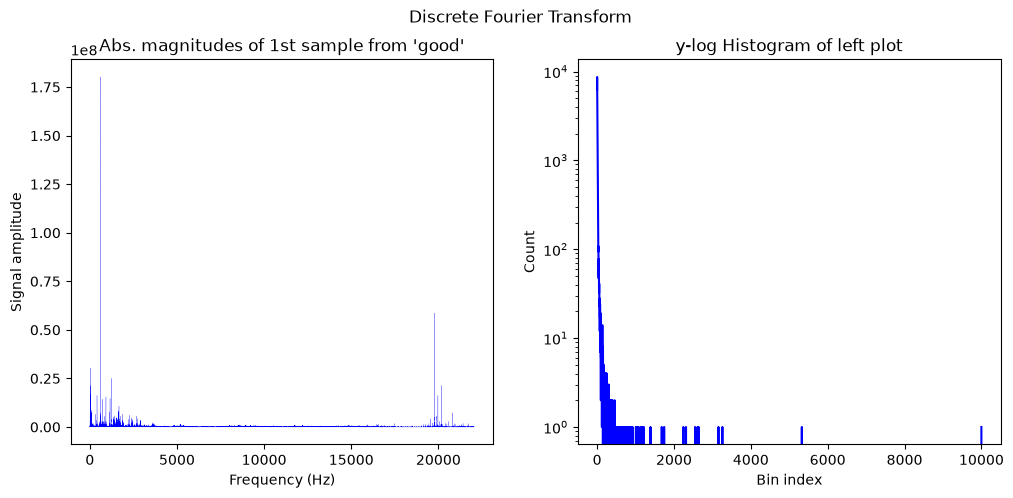

In [15]:
sampl = train_fft_g[0]
x = np.zeros((sampl.size))
for i in range(sampl.size):
    x[i] = i*(rate/sampl.size/2)
    
fig, ax = plt.subplots(1,2)
fig.set_size_inches(12,5)
fig.suptitle("Discrete Fourier Transform")

ax[0].plot(x, sampl, lw=0.15, color="blue")
ax[0].set_xlabel("Frequency (Hz)")
ax[0].set_ylabel("Signal amplitude")
ax[0].set_title("Abs. magnitudes of 1st sample from 'good'")

h = np.histogram(sampl, bins=binN)[0]
ax[1].semilogy(h, color="blue")
ax[1].set_xlabel("Bin index")
ax[1].set_ylabel("Count")
ax[1].set_title("y-log Histogram of left plot")

plt.show()

In [16]:
# Trying first on just magnitudes, before complex / more-dimensional features.

In [17]:
# Targets already exist from before.

## GOOD vs BROKEN
inp_gb = get_features(train_fft_g, train_fft_b)
model_gb = create_svm(target_gb, inp_gb)
scores = cross_val_score(model_gb, inp_gb, target_gb, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## BROKEN vs HEAVY
inp_bh = get_features(train_fft_b, train_fft_h)
model_bh = create_svm(target_bh, inp_bh)
scores = cross_val_score(model_bh, inp_bh, target_bh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## GOOD vs HEAVY
inp_gh = get_features(train_fft_g, train_fft_h)
model_gh = create_svm(target_gh, inp_gh)
#scores = cross_val_score(model_gh, inp_gh, target_gh, cv=5)
#print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print("Cross validating this one freezes everything for some reason.")

Input shape: (229, 10000)
Accuracy: 1.000
5-fold cross validation: 1.000 +/- 0.000

Input shape: (252, 10000)
Accuracy: 1.000
5-fold cross validation: 1.000 +/- 0.000

Input shape: (233, 10000)
Accuracy: 1.000
Cross validating this one freezes everything for some reason.


In [18]:
final_inp_fft = build_inputs(train_fft_g, train_fft_b, train_fft_h)

print(f"Final input array shape: {test.shape}")
r = three_fold_predict(final_inp_fft)
print()
print("Output predictions (sanity check):")
print(r)

Input shape: (105, 10000)
Input shape: (124, 10000)
Input shape: (128, 10000)
Final input array shape: (357, 10000)

Output predictions (sanity check):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.

In [19]:
# NOTE: This is MAGNITUDE.
#    Remove the np.abs() for the actual, complex result.
test_fft_g = np.abs(rfft(test_good))
test_fft_b = np.abs(rfft(test_broken))
test_fft_h = np.abs(rfft(test_heavy))

In [20]:
print("Validating vs. test_cut, for FFT+Histogram model.")
print()

test_inp_fft = build_inputs(test_fft_g, test_fft_b, test_fft_h)
print(f"Combined input shape: {test_inp_fft.shape}")

r = three_fold_predict(test_inp_fft)
test_acc = accuracy_score(o, r)
print()
print(f"Test/validation accuracy: {test_acc:.3f}, or {test_acc*100:.1f}%")

Validating vs. test_cut, for FFT+Histogram model.

Input shape: (669, 10000)
Input shape: (665, 10000)
Input shape: (687, 10000)
Combined input shape: (2021, 10000)

Test/validation accuracy: 0.879, or 87.9%


In [21]:
################ NEW FEATURES: RANKED FOURIER TRANSFORM ################
# Take the N largest frequencies.

In [22]:
N = 200
def build_fft_ranked(inp):
    s = np.argsort(inp)[:, -N:]
    out = np.zeros((s.shape))
    for i in range(out.shape[0]):
        out[i] = s[i]*i*(rate/out.shape[0]/2)
    return np.sort(out)

In [23]:
train_fft_sort_g = build_fft_ranked(train_fft_g)
train_fft_sort_b = build_fft_ranked(train_fft_b)
train_fft_sort_h = build_fft_ranked(train_fft_h)
print(train_fft_sort_g[5, :])

[6.300000e+04 7.980000e+04 8.085000e+04 8.190000e+04 8.295000e+04
 8.610000e+04 1.575000e+05 3.265500e+05 3.780000e+05 9.807000e+05
 1.305150e+06 1.306200e+06 1.307250e+06 1.308300e+06 1.879500e+06
 1.909950e+06 1.911000e+06 1.921500e+06 1.928850e+06 1.930950e+06
 1.934100e+06 1.938300e+06 1.940400e+06 1.943550e+06 1.944600e+06
 1.946700e+06 1.947750e+06 1.948800e+06 1.949850e+06 1.950900e+06
 1.951950e+06 1.953000e+06 1.954050e+06 1.955100e+06 1.956150e+06
 1.957200e+06 1.958250e+06 1.959300e+06 1.960350e+06 1.961400e+06
 1.962450e+06 1.963500e+06 1.964550e+06 1.965600e+06 1.966650e+06
 1.967700e+06 1.968750e+06 1.969800e+06 1.970850e+06 1.971900e+06
 1.972950e+06 1.974000e+06 1.975050e+06 1.976100e+06 1.977150e+06
 1.979250e+06 1.981350e+06 1.982400e+06 1.983450e+06 2.286900e+06
 2.287950e+06 2.289000e+06 2.291100e+06 2.613450e+06 2.614500e+06
 2.615550e+06 2.619750e+06 2.937900e+06 2.938950e+06 2.940000e+06
 2.941050e+06 2.942100e+06 2.943150e+06 2.944200e+06 2.945250e+06
 2.946300e

In [24]:
# Targets already exist from before.

## GOOD vs BROKEN
inp_gb = np.concatenate((train_fft_sort_g, train_fft_sort_b))
print(f"Input shape: {inp_gb.shape}")
model_gb = create_svm(target_gb, inp_gb)
scores = cross_val_score(model_gb, inp_gb, target_gb, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## BROKEN vs HEAVY
inp_bh = np.concatenate((train_fft_sort_b, train_fft_sort_h))
print(f"Input shape: {inp_bh.shape}")
model_bh = create_svm(target_bh, inp_bh)
scores = cross_val_score(model_bh, inp_bh, target_bh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## GOOD vs HEAVY
inp_gh = np.concatenate((train_fft_sort_g, train_fft_sort_h))
print(f"Input shape: {inp_gh.shape}")
model_gh = create_svm(target_gh, inp_gh)
scores = cross_val_score(model_gh, inp_gh, target_gh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")

Input shape: (229, 200)
Accuracy: 1.000
5-fold cross validation: 0.952 +/- 0.085

Input shape: (252, 200)
Accuracy: 0.961
5-fold cross validation: 0.984 +/- 0.015

Input shape: (233, 200)
Accuracy: 0.957
5-fold cross validation: 0.974 +/- 0.021
